# 04: Image-only CNN Evaluation

Out-of-fold evaluation of the image-only CNN on UTSW (617 patients), with the same metrics and plots as `03_clinical_model.ipynb`. Training ran on Colab (`src/train_cnn.py`); the per-fold predictions and logs were downloaded to `results/cnn` (Round 1) and `results/cnn_v2` (Round 2).

- **Round 1:** initial configuration (batch 4, learning rate 1e-3, weight decay 1e-2).
- **Tuning:** 8 configurations on folds 0 and 1, scored by mean best stop-set loss. A change had to beat the baseline by more than its seed-to-seed spread. A more in-depth explanation in the Tuning Section Below. 
- **Round 2:** the selected configuration, run on all 5 folds.

All scores here are development estimates: the tuning used these patients, and Round 1's results were seen before Round 2 was chosen. The external UCSF run is the only unbiased test. Threshold metrics use the training-fold mutant rate as the cutoff, as in notebook 03.

## Setup
Imports, paths, building the cohort, and three helper functions.

Here are the 3 helper functions: 
- `stitch_folds` adds a model's out-of-fold probabilities to `results/oof_predictions.csv`. Required since the probabilities of each fold are held in separate csv files. 
- `score_model` adds its row to `results/model_comparison.csv`. 
- `compare` function to compare AUROC scores between two models.

Functions are safe to rerun. 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_auc_score, roc_curve)

from src.cohort import build_cohort
from src.config import PROJECT_ROOT
from src.metrics import bootstrap_ci, paired_auroc_difference, summarize, threshold_predictions

R1_DIR = PROJECT_ROOT / "results" / "cnn"
R2_DIR = PROJECT_ROOT / "results" / "cnn_v2"
OOF_PATH = PROJECT_ROOT / "results" / "oof_predictions.csv"
CMP_PATH = PROJECT_ROOT / "results" / "model_comparison.csv"

cohort = build_cohort(expected_n=617, verbose=False)


def stitch_folds(run_dir, column):
    """Join the five per-fold prediction files, check them against the manifest, and add them to the
    shared out-of-fold file as `column`."""
    pred = pd.concat([pd.read_csv(run_dir / f"fold{k}_pred.csv") for k in range(5)], ignore_index=True)
    assert len(pred) == 617 and pred["patient_id"].is_unique
    check = pred.merge(cohort[["patient_id", "fold", "idh"]], on="patient_id", suffixes=("", "_manifest"))
    assert len(check) == 617
    assert (check["fold"] == check["fold_manifest"]).all() and (check["idh"] == check["idh_manifest"]).all()
    assert pred["cnn_prob"].between(0, 1).all()
    oof = pd.read_csv(OOF_PATH).drop(columns=column, errors="ignore")
    oof = oof.merge(pred[["patient_id", "cnn_prob"]].rename(columns={"cnn_prob": column}),
                    on="patient_id", how="left")
    assert oof[column].notna().all()
    oof.to_csv(OOF_PATH, index=False)
    print(f"{column}: stitched 617 predictions; ids, folds and labels match the manifest")


def score_model(name, prob):
    """Pooled metrics with bootstrap CIs, per-fold AUROC, and the row saved to model_comparison.csv.
    Returns the 0/1 predictions at the training-fold-rate cutoff."""
    pred = threshold_predictions(prob, y, folds)
    row = {"model": name, "n_patients": len(y), **summarize(y, prob, pred)}
    row["auroc_ci_low"], row["auroc_ci_high"] = bootstrap_ci(y, prob, roc_auc_score)
    row["pr_auc_ci_low"], row["pr_auc_ci_high"] = bootstrap_ci(y, prob, average_precision_score)
    row = pd.DataFrame([row]).round(3)
    old = pd.read_csv(CMP_PATH)
    pd.concat([old[old["model"] != name], row], ignore_index=True).to_csv(CMP_PATH, index=False)
    print(row.set_index("model").T)
    print("per-fold AUROC:", np.round([roc_auc_score(y[folds == k], prob[folds == k]) for k in np.unique(folds)], 3))
    return pred


def compare(label_a, prob_a, label_b, prob_b):
    """Paired bootstrap of the AUROC difference between two models scored on the same patients."""
    diff, (lo, hi) = paired_auroc_difference(y, prob_a, prob_b)
    print(f"AUROC {label_a} minus {label_b}: {diff:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

## Round 1: initial configuration
First full 5-fold run. The 1st round had a very simple grid search for hyperparameter tuning. Only learning rate and weight decay were tuned: `[lr:0.001, 0.0003; wd: 0.01, 0.0001]`, which provided 4 configurations.

The paired bootstrap compares this model with the age-only model on the same 617 patients.

In [3]:
stitch_folds(R1_DIR, "image_cnn_prob")
oof = pd.read_csv(OOF_PATH)
y, folds = oof["idh"].to_numpy(), oof["fold"].to_numpy()
p_age, p_r1 = oof["clinical_age_prob"].to_numpy(), oof["image_cnn_prob"].to_numpy()

pred_r1 = score_model("image_cnn", p_r1)
print("prevalence (PR-AUC baseline):", round(y.mean(), 3),
      "| Brier of always predicting prevalence:", round(y.mean() * (1 - y.mean()), 3))
compare("image CNN round 1", p_r1, "age-only", p_age)

image_cnn_prob: stitched 617 predictions; ids, folds and labels match the manifest
model           image_cnn
n_patients        617.000
auroc               0.888
pr_auc              0.809
brier               0.111
accuracy            0.799
precision           0.611
recall              0.800
specificity         0.799
auroc_ci_low        0.856
auroc_ci_high       0.917
pr_auc_ci_low       0.750
pr_auc_ci_high      0.860
per-fold AUROC: [0.85  0.942 0.946 0.835 0.9  ]
prevalence (PR-AUC baseline): 0.284 | Brier of always predicting prevalence: 0.203
AUROC image CNN round 1 minus age-only: +0.008 (95% CI -0.030 to +0.042)


### Loss curves
Training loss and stop-set loss (the held-out slice of the training folds used only to choose the stopping epoch) for each held-out fold. The dashed vertical line marks the epoch kept while the dotted horizontal line is the loss of always predicting the mutant rate. The loss curves were used to evaluate overfitting by comparing the training loss vs. the stop set loss. A trend of a falling training loss curve with a rising stop set loss curve is a clear indictor of overfitting. 

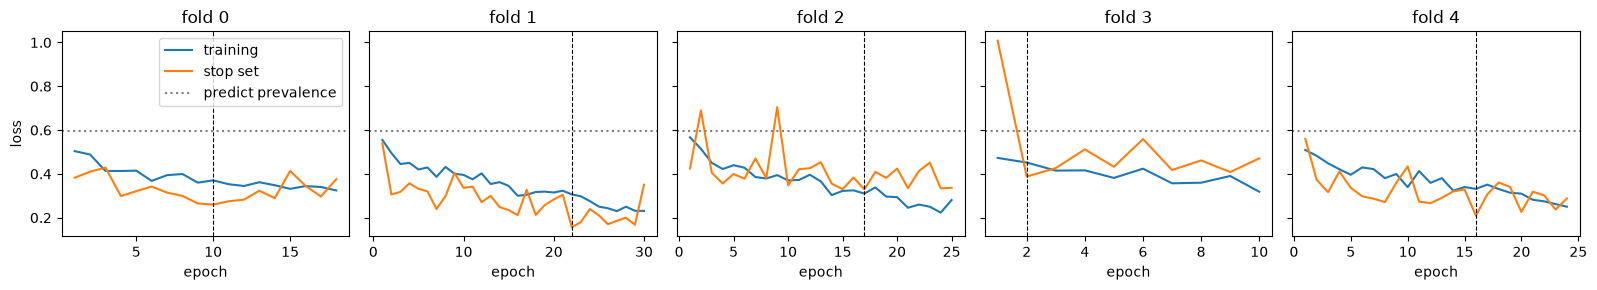

In [5]:
def plot_loss_curves(run_dir):
    h = pd.read_csv(run_dir / "history.csv")
    runs = pd.read_csv(run_dir / "runs.csv")
    best = runs[runs["mode"] == "final"].set_index("fold")["best_epoch"]
    m = y.mean()
    prevalence_loss = -(m * np.log(m) + (1 - m) * np.log(1 - m))
    groups = list(h[h["mode"] == "final"].groupby("fold"))
    fig, axes = plt.subplots(1, len(groups), figsize=(3.2 * len(groups), 3), sharey=True, squeeze=False)
    for ax, (fold, g) in zip(axes[0], groups):
        ax.plot(g["epoch"], g["train_loss"], label="training")
        ax.plot(g["epoch"], g["stop_loss"], label="stop set")
        ax.axhline(prevalence_loss, color="gray", ls=":", label="predict prevalence")
        ax.axvline(best[fold], color="k", ls="--", lw=0.8)
        ax.set(title=f"fold {fold}", xlabel="epoch")
    axes[0][0].set_ylabel("loss")
    axes[0][0].legend()
    plt.tight_layout()
    plt.show()


plot_loss_curves(R1_DIR)

## Tuning (Round 2)
For round 2, training/tuning was performed differently and with an expanded hyperparameter tuning. 
Round 1 tuning only trained based on the results of fold 0, this results in a stop set with about 74 patients and ~21 mutants. By tuning with two folds, the stop set patient size doubles (148) and should reduce sampling noise. For the baseline, it was trained on three seeds to measure seed-to-seed noise (this meant with two folds and 3 seeds, the baseline configuration was run 6 times). From the seed-to-seed baseline, the `spread` was obtained by taking the largest minus the smallest seed mean stop set loss. 
Each configuration was run on folds 0 and 1, then scored by the mean best stop set loss. A configuration only counts as better if it beats the baseline mean by more than the spread.

Here were 8 configurations (weight decay was kept constant here at 0.01):
1. [batch=4; lr=0.001] (Baseline)
2. [batch=4; lr=0.0003]
3. [batch=8; lr=0.001]
4. [batch=8; lr=0.0003]
5. [batch=16; lr=0.001]
6. [batch=16; lr=0.0003]
7. [batch=4; lr=0.001 + cosine decay]
8. [batch=4; lr=0.001; width doubled]

In [6]:
runs2 = pd.read_csv(R2_DIR / "runs.csv")
dev = runs2[runs2["mode"] == "dev"]

# Per (configuration, seed): mean best stop-set loss over folds 0 and 1; then average over seeds
per_seed = dev.groupby(["config", "seed"])["stop_set_loss"].mean()
summary = per_seed.groupby("config").mean().sort_values().to_frame("stop_set_loss")
base = per_seed["baseline"]
spread = base.max() - base.min()
summary["gain_vs_baseline"] = base.mean() - summary["stop_set_loss"]
summary["beats_noise"] = summary["gain_vs_baseline"] > spread
print(f"baseline seeds: {base.round(3).tolist()} | spread {spread:.3f}")
summary.round(3)

baseline seeds: [0.272, 0.231, 0.228] | spread 0.044


,stop_set_loss,gain_vs_baseline,beats_noise
config,,,
b8_lr0.001_wd0.01,0.184,0.060,True
b8_lr0.0003_wd0.01,0.197,0.046,True
cosine,0.202,0.042,False
b4_lr0.0003_wd0.01,0.213,0.031,False
b16_lr0.001_wd0.01,0.214,0.030,False
b16_lr0.0003_wd0.01,0.223,0.021,False
baseline,0.244,-0.000,False
width2,0.250,-0.006,False


Two configurations pass, both with batch size 8. Batch 8 with learning rate 0.001 (`b8_lr0.001_wd0.01`) had the lowest loss and was used for Round 2. This is modest evidence: the seed-to-seed standard deviation of these two-fold means is about 0.025, only the baseline had multiple seeds, and the winner is the best of seven. Width 2 gave no gain, and cosine decay narrowly missed the threshold.

## Round 2: selected configuration
The same 5-fold procedure with batch size 8. The paired comparisons cover whether the image model beats age alone and whether tuning mattered. Neither interval accounts for the tuning itself or for retraining noise.

In [7]:
runs2_final = runs2[runs2["mode"] == "final"]
assert len(runs2_final) == 5 and (runs2_final["config"] == "b8_lr0.001_wd0.01").all()   # right config, all folds

stitch_folds(R2_DIR, "image_cnn_v2_prob")
p_r2 = pd.read_csv(OOF_PATH)["image_cnn_v2_prob"].to_numpy()

pred_r2 = score_model("image_cnn_v2", p_r2)
compare("image CNN round 2", p_r2, "age-only", p_age)
compare("image CNN round 2", p_r2, "image CNN round 1", p_r1)

image_cnn_v2_prob: stitched 617 predictions; ids, folds and labels match the manifest
model           image_cnn_v2
n_patients           617.000
auroc                  0.907
pr_auc                 0.822
brier                  0.105
accuracy               0.838
precision              0.679
recall                 0.811
specificity            0.848
auroc_ci_low           0.880
auroc_ci_high          0.930
pr_auc_ci_low          0.768
pr_auc_ci_high         0.867
per-fold AUROC: [0.875 0.935 0.958 0.874 0.923]
AUROC image CNN round 2 minus age-only: +0.027 (95% CI -0.006 to +0.057)
AUROC image CNN round 2 minus image CNN round 1: +0.019 (95% CI +0.001 to +0.038)


### Loss curves (Round 2)

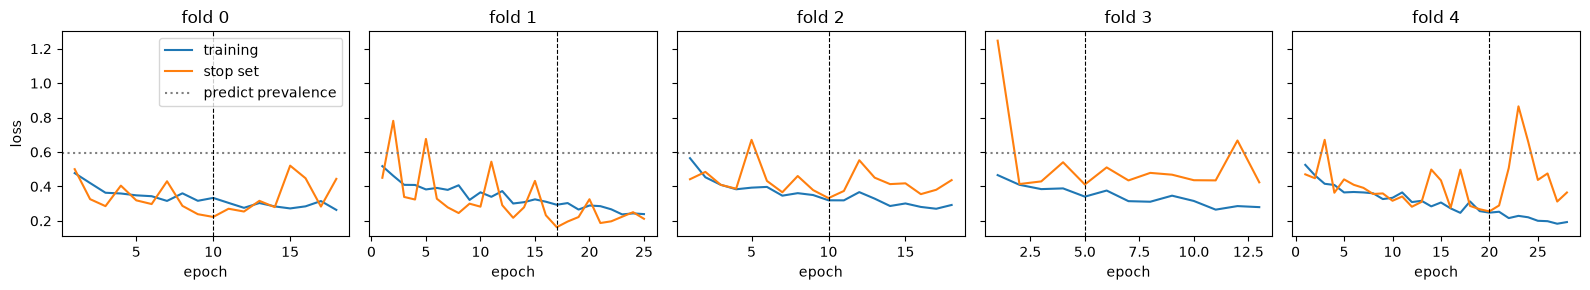

In [8]:
plot_loss_curves(R2_DIR)

## Comparison plots
Age-only against both CNN rounds on the same 617 out-of-fold predictions. Calibration uses five equal-count bins.

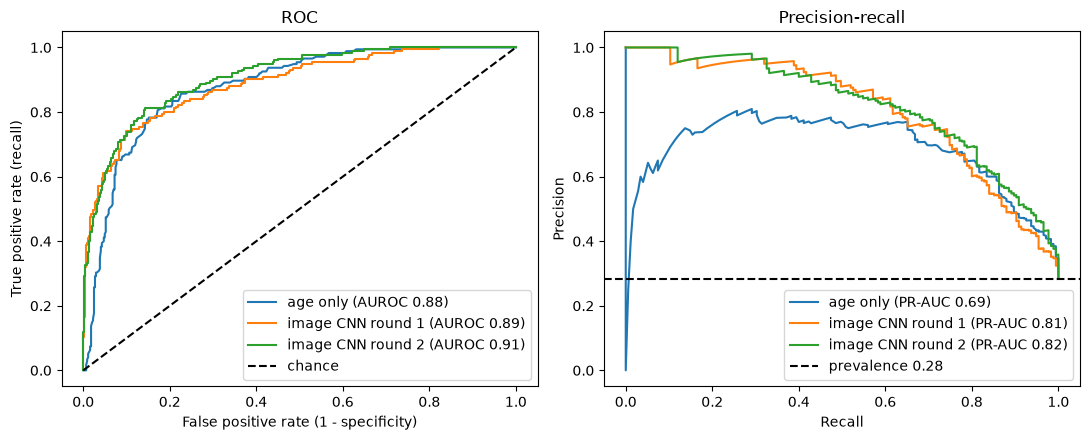

In [ ]:
models = {"age only": p_age, "image CNN round 1": p_r1, "image CNN round 2": p_r2}

# Plot ROC and PR curves for all three models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, prob in models.items():
    fpr, tpr, _ = roc_curve(y, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y, prob):.2f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y, prob):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)", title="ROC")
axes[1].axhline(y.mean(), color="k", ls="--", label=f"prevalence {y.mean():.2f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

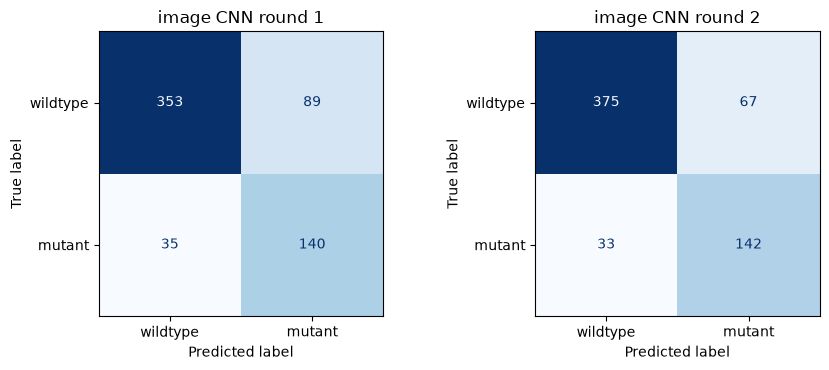

In [ ]:
# Plot confusion matrices for the two image CNNs
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, pred) in zip(axes, {"Image CNN round 1": pred_r1, "Image CNN round 2": pred_r2}.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["wildtype", "mutant"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

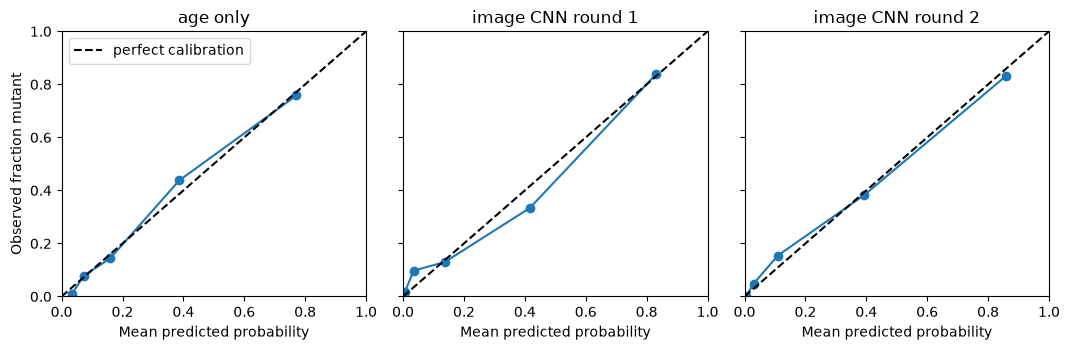

In [11]:
# Plot calibration curves for all three models
fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models), 3.6), sharex=True, sharey=True)
for ax, (name, prob) in zip(axes, models.items()):
    observed, predicted = calibration_curve(y, prob, n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, marker="o")
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.set(xlabel="Mean predicted probability", title=name, xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Observed fraction mutant")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

## Summary
Out-of-fold AUROC on 617 UTSW patients (95% bootstrap CI): age-only 0.88 (0.85 to 0.91), image CNN round 1 0.89 (0.86 to 0.92), round 2 0.91 (0.88 to 0.93).

- The round 2 minus age-only AUROC difference is +0.027 (95% CI -0.006 to +0.057). The interval includes 0, so by the rule set in advance this is not called an improvement over age. Round 2 minus round 1 is +0.019 (+0.001 to +0.038), barely clearing 0, and that interval ignores the tuning and retraining noise.
- PR-AUC, Brier score, and the confusion matrix all lean in the CNN's favor (round 2: PR-AUC 0.82, Brier 0.105, versus 0.69 and 0.123 for age), but those comparisons were not pre-specified or tested. Calibration is close to the diagonal.
- Per-fold AUROC is 0.85, 0.94, 0.95, 0.84, 0.90 in round 1 and 0.88, 0.94, 0.96, 0.87, 0.92 in round 2.

**Limits:** these are development estimates, and the UCSF run is the only unbiased test. There is one training run per fold, and GPU training is not exactly reproducible. Early stopping on a stop set of about 74 patients is noisy. No data augmentation was used. The bootstrap intervals cover patient sampling only. 